# TouNum, deliverable 2: denoising photos with convolutional autoencoders

CESI Data Science team. Prototype of the automatic image captioning workflow.

---
## 0. Business context and goal

TouNum digitises documents on a production line, and image quality varies: some scans are noisy or blurry.
The captioning module (deliverable 3) works on photos, so it is worth cleaning them before they reach it.
This deliverable covers the pre-processing step of the workflow:

1. Filtering: keep only the photos (deliverable 1);
2. **Pre-processing: remove the noise from the photos (this deliverable)**;
3. Captioning (deliverable 3).

TouNum provided 148 noisy RGB photos. We build **convolutional autoencoders** that take a noisy photo and return
a cleaned one, and we compare them with the classical convolution filters (mean, Gaussian, median). The clean
originals of the 148 photos turned out to be available (section 3), which lets us measure everything against the
real noise, and use part of the real pairs to adapt the models to it.

### Outline
| Section | Content |
|---|---|
| 1 | Environment |
| 2 | Loading the TouNum dataset |
| 3 | What kind of noise? Analysis with the clean originals |
| 4 | Training data: synthetic noise on clean photos, and real pairs |
| 5 | Baseline: classical convolution filters |
| 6 | Convolutional autoencoders: architecture, loss, optimiser |
| 7 | Training and learning curves |
| 8 | Evaluation by noise level |
| 9 | Case study: the real TouNum images, fine-tuning, when to denoise, effect on the photo filter |
| 10 | Conclusion, limits and next steps |

### How to run it
`bash scripts/run_notebook.sh 2 full` rebuilds the `.ipynb` from this `.py` file and runs it. Most of the time
goes into training: minutes on an NVIDIA GPU, hours on a CPU. It needs `Dataset Livrable 2.zip` and the
deliverable 1 archive `Dataset Livrable 1 - Photo.zip` at the project root, and deliverable 1 must have been run
once (its image cache and its saved classifier are reused). `bash scripts/run_notebook.sh 2 quick` runs a very
short version to check that everything executes; it never touches the deliverable or the saved models.

## 1. Environment

In [1]:
import io
import os
import sys
import json
import time
import inspect
import tempfile
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")      # hide TensorFlow C++ logs (GPU autotuning notices)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import tounum_gpu
tounum_gpu.setup()                                      # use the NVIDIA GPU if there is one (src/tounum_gpu.py)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, Markdown
import tensorflow as tf
import keras

from tounum_cls import config as cls_config, data as cls_data, modeling as cls_modeling
from tounum_denoise import config, data, modeling, evaluation

QUICK = os.environ.get("TOUNUM_QUICK") == "1"
EPOCHS = 1 if QUICK else 60                 # upper bound: early stopping decides when to stop
FT_EPOCHS = 1 if QUICK else 100             # fine-tuning on the real pairs (section 9.2), same principle

keras.utils.set_random_seed(config.SEED)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | Keras {keras.__version__} | numpy {np.__version__}")
print("GPU:", tf.config.list_physical_devices("GPU") or "none (running on CPU)")
print(f"Seed: {config.SEED} | QUICK mode: {QUICK} | epochs: {EPOCHS}")

I0000 00:00:1791304672.624406 2259095 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791304673.161979 2259095 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.13 | TensorFlow 2.21.0 | Keras 3.15.1 | numpy 2.5.3
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42 | QUICK mode: False | epochs: 60


## 2. Loading the TouNum dataset

`Dataset Livrable 2.zip` holds the noisy photos as JPEG files. `data.extract_noisy()` unpacks them once into
`data/noisy/`, and `data.load_noisy()` reads them at full size with ImageIO (as RGB `uint8` arrays) and builds a
table with their size and an estimate of their noise level (explained in section 3.3).

In [2]:
noisy_paths = data.extract_noisy()
noisy_images, noisy_info = data.load_noisy(noisy_paths)
print(f"{len(noisy_images)} images loaded from {config.NOISY_ZIP.name}")
display(noisy_info.head())
sizes = noisy_info.groupby(["width", "height"]).size().sort_values(ascending=False)
print("Most common sizes (width x height):", ", ".join(f"{w}x{h} ({n})" for (w, h), n in sizes.head(4).items()))

148 images loaded from Dataset Livrable 2.zip


,file,width,height,noise_sigma
0,noisy_001.jpg,640,426,8.925
1,noisy_002.jpg,640,482,2.422
2,noisy_003.jpg,480,640,7.884
3,noisy_004.jpg,518,600,1.479
4,noisy_005.jpg,640,480,7.662


Most common sizes (width x height): 640x480 (41), 640x427 (16), 480x640 (7), 500x375 (6)


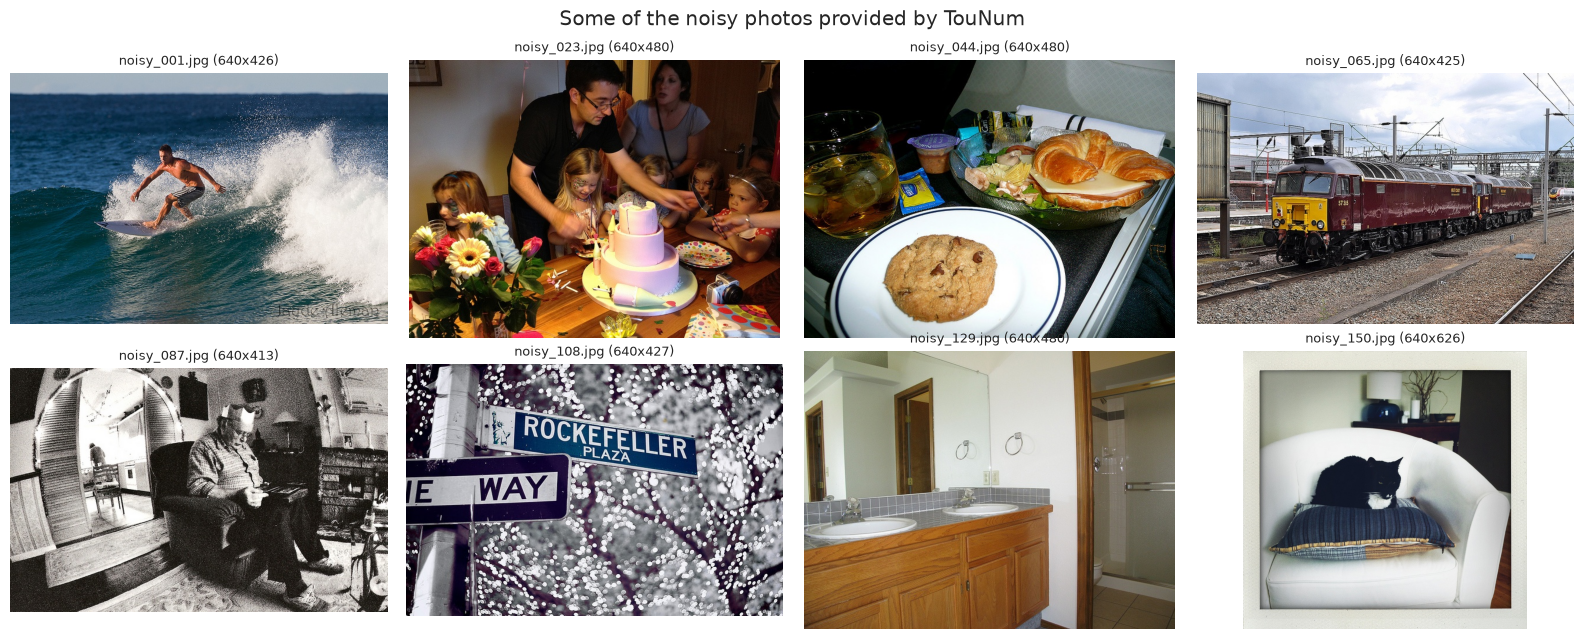

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, i in zip(axes.ravel(), np.linspace(0, len(noisy_images) - 1, 8).astype(int)):
    ax.imshow(noisy_images[i])
    ax.set_title(f"{noisy_info.file[i]} ({noisy_info.width[i]}x{noisy_info.height[i]})", fontsize=9)
    ax.axis("off")
plt.suptitle("Some of the noisy photos provided by TouNum")
plt.tight_layout()
plt.show()

At this scale the noise is hard to see. It shows up when we zoom in on a flat area (sky, wall, skin):

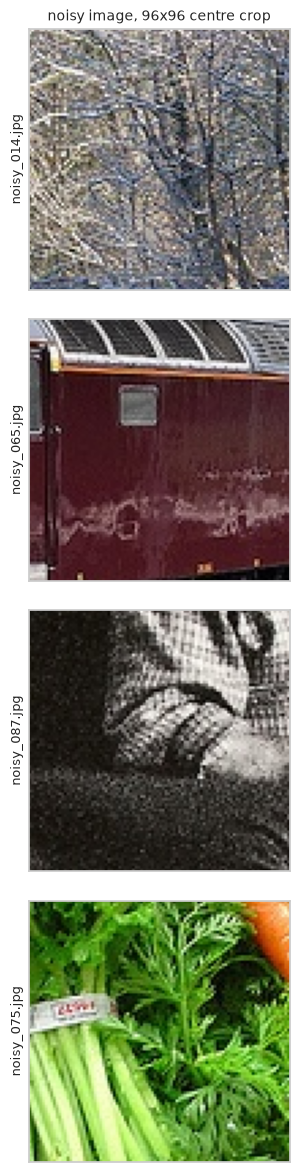

In [4]:
def center_crop(img, size=96):
    h, w = img.shape[:2]
    return img[h // 2 - size // 2: h // 2 + size // 2, w // 2 - size // 2: w // 2 + size // 2]


worst = noisy_info["noise_sigma"].nlargest(4).index
fig = evaluation.show_grid({"noisy image, 96x96 centre crop": [center_crop(noisy_images[i]) for i in worst]},
                           [noisy_info.file[i] for i in worst], size=3)
plt.show()

## 3. What kind of noise?

### 3.1 The clean originals
These photos are 640 pixels wide and look like MS COCO pictures, the dataset we use for captioning in
deliverable 3. Comparing small thumbnails of the noisy files with the COCO 2017 training images confirmed it:
every noisy file has an exact match among the COCO images with ids 1308 to 2349
(`scripts/find_noisy_originals.py`, run once, stored in `src/tounum_denoise/noisy_originals.csv`).

This gives us something rare in a denoising project: the **clean ground truth** for the real noisy images.
We use it in three ways:
- to measure the real noise exactly, and build a training noise that looks like it (this section);
- to adapt the models to the real noise with part of the pairs (section 9.2);
- to score the denoisers on real images they never saw (section 9), not only on synthetic noise.

In [5]:
originals = data.load_originals(noisy_paths)
assert all(o.shape == n.shape for o, n in zip(originals, noisy_images))
residuals = [n.astype(np.float32) - o.astype(np.float32) for n, o in zip(noisy_images, originals)]
noisy_info["true_sigma"] = [r.std() for r in residuals]
noisy_info["psnr_noisy"] = [evaluation.psnr(data.to_float(o), data.to_float(n)) for o, n in zip(originals, noisy_images)]
display(noisy_info[["true_sigma", "noise_sigma", "psnr_noisy"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
true_sigma,148.0,3.463,1.557,0.607,2.400,3.174,4.316,9.750
noise_sigma,148.0,5.116,3.246,0.583,2.627,4.567,6.738,24.227
psnr_noisy,148.0,38.198,3.969,28.351,35.428,38.099,40.523,52.468


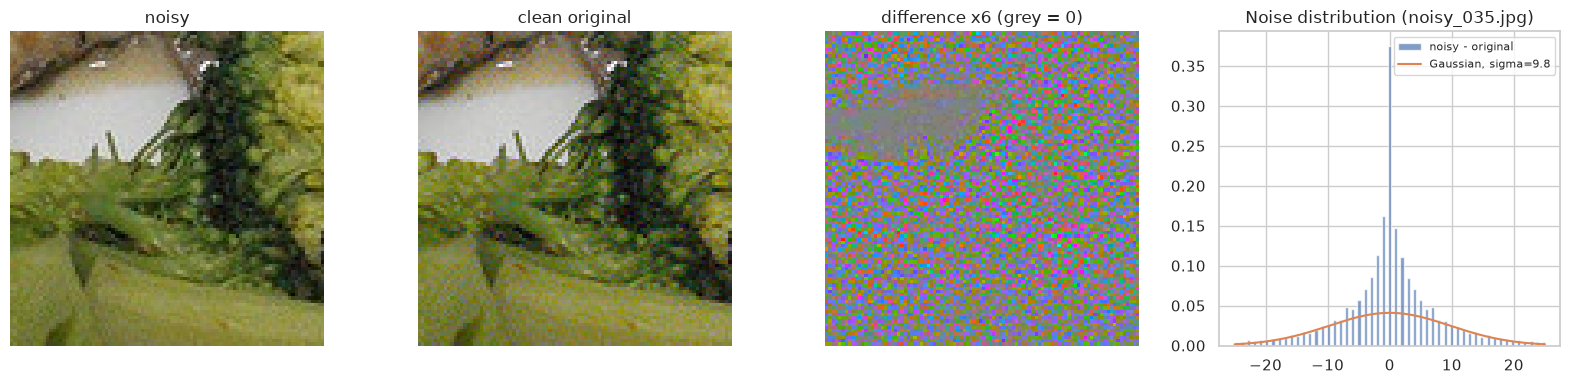

In [6]:
i = int(noisy_info["true_sigma"].idxmax())
r = residuals[i]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(axes[:3], [center_crop(noisy_images[i]), center_crop(originals[i]),
                                     np.clip(center_crop(r) * 6 + 128, 0, 255).astype(np.uint8)],
                          ["noisy", "clean original", "difference x6 (grey = 0)"]):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
xs = np.linspace(-25, 25, 200)
axes[3].hist(r.ravel(), bins=101, range=(-25, 25), density=True, alpha=0.7, label="noisy - original")
axes[3].plot(xs, np.exp(-xs**2 / (2 * r.std() ** 2)) / (r.std() * np.sqrt(2 * np.pi)), label=f"Gaussian, sigma={r.std():.1f}")
axes[3].set_title(f"Noise distribution ({noisy_info.file[i]})")
axes[3].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3.2 Characteristics of the real noise
The difference image above is coloured: the noise seems to change the colours more than the brightness. To check
it, we convert the difference to the **YCbCr** space used by JPEG, where Y is the brightness and Cb, Cr are two
colour differences (blue minus brightness, red minus brightness). As a reference, we also re-encode each clean
original as JPEG quality 95, the format of the noisy files: this gives the error that the re-encoding alone adds.

In [7]:
YCC = data.RGB_TO_YCBCR


def noise_profile(noisy, orig):
    """Where the noise is (brightness Y or colour Cb, Cr), how much colour is kept, and how smooth the noise is."""
    res = (noisy.astype(np.float32) - orig) @ YCC.T
    reenc = (data.jpeg_roundtrip(orig).astype(np.float32) - orig) @ YCC.T
    colour = (orig.astype(np.float32) @ YCC.T)[..., 1:].reshape(-1, 2)
    noisy_colour = colour + res[..., 1:].reshape(-1, 2)
    cb = res[..., 1]
    return {"mean (bias)": res.mean(), "Y std": res[..., 0].std(), "Y std, JPEG re-encoding only": reenc[..., 0].std(),
            "Cb std": cb.std(), "Cr std": res[..., 2].std(),
            "colour kept (slope)": (colour * noisy_colour).sum() / (colour * colour).sum(),
            "Cb neighbour correlation": np.corrcoef(cb[:, :-1].ravel(), cb[:, 1:].ravel())[0, 1]}


stats = pd.DataFrame([noise_profile(n, o) for n, o in zip(noisy_images, originals)])
display(stats.describe().T[["mean", "25%", "50%", "75%"]])


def jpeg_settings(source):
    """Mean luminance quantisation step and chroma sampling factors of a JPEG file."""
    with Image.open(source) as im:
        return float(np.mean(im.quantization[0])), im.layer[1][1:3]


buf = io.BytesIO()
Image.fromarray(originals[0]).save(buf, format="JPEG", quality=95, subsampling=0)
file_settings = {jpeg_settings(p) for p in noisy_paths}
print(f"JPEG settings of the 148 noisy files (quantisation step, chroma sampling): {file_settings}")
print(f"JPEG settings of a re-encoding at quality 95 without chroma subsampling: {jpeg_settings(buf)}")

,mean,25%,50%,75%
mean (bias),0.006,-0.006,2.734e-04,0.008
Y std,1.008,0.771,9.644e-01,1.238
"Y std, JPEG re-encoding only",0.956,0.701,9.186e-01,1.192
Cb std,2.469,1.509,2.352e+00,3.112
Cr std,2.237,1.446,1.973e+00,2.783
colour kept (slope),0.850,0.928,9.650e-01,0.981
Cb neighbour correlation,0.445,0.354,4.511e-01,0.541


JPEG settings of the 148 noisy files (quantisation step, chroma sampling): {(5.765625, (1, 1))}
JPEG settings of a re-encoding at quality 95 without chroma subsampling: (5.765625, (1, 1))


The strength of the colour noise can also be compared with how colourful each pixel is (its saturation, the
distance of (Cb, Cr) from grey), once the small loss of colour measured above is removed:

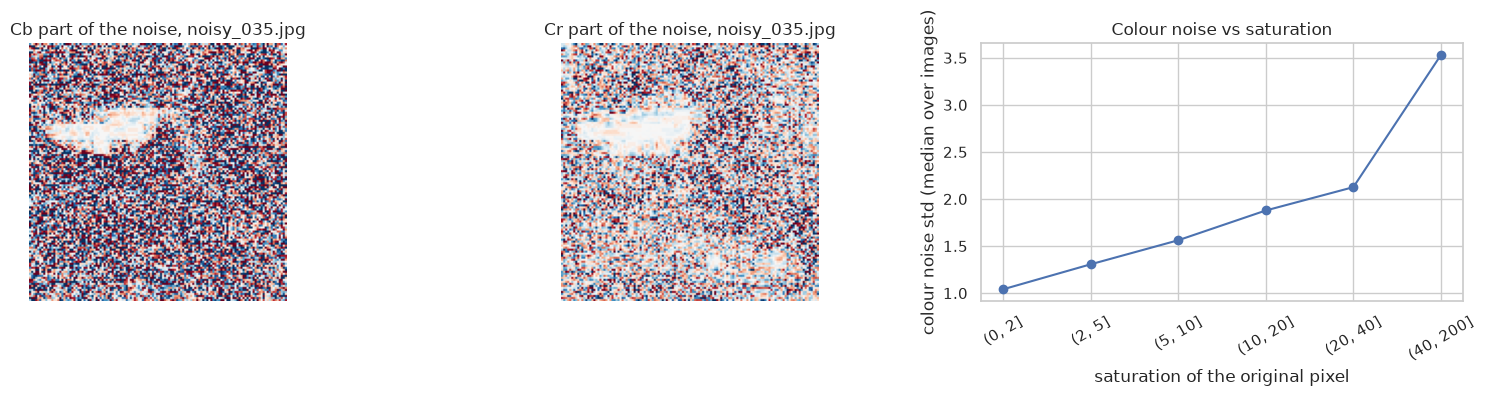

**Results.** The noise has no bias (mean +0.006). In the brightness channel Y its standard deviation is 0.96 (median over the 148 images), the same as a plain JPEG re-encoding of the original (0.92): **the brightness is left untouched**. The noise is in the colour channels (Cb 2.35, Cr 1.97). The noisy images also keep 97% of the original colour (a slight loss of saturation), neighbouring pixels share part of their noise (correlation 0.45), and the colour noise grows with saturation, from 1.0 on grey pixels to 3.5 on the most colourful ones.

In [8]:
sat_bins = [0, 2, 5, 10, 20, 40, 200]
per_bin = []
for n, o in zip(noisy_images, originals):
    colour = (o.astype(np.float32) @ YCC.T)[..., 1:].reshape(-1, 2)
    noisy_colour = (n.astype(np.float32) @ YCC.T)[..., 1:].reshape(-1, 2)
    slope = (colour * noisy_colour).sum() / (colour * colour).sum()
    rest = np.hypot(*(noisy_colour - slope * colour).T) / np.sqrt(2)
    per_bin.append(pd.Series(rest).groupby(pd.cut(np.hypot(*colour.T), sat_bins), observed=False).mean())
by_saturation = pd.concat(per_bin, axis=1).median(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, k, name in zip(axes[:2], (1, 2), ("Cb", "Cr")):
    ax.imshow(center_crop(residuals[i] @ YCC.T, 128)[..., k], cmap="RdBu", vmin=-12, vmax=12)
    ax.set_title(f"{name} part of the noise, {noisy_info.file[i]}")
    ax.axis("off")
axes[2].plot([str(b) for b in by_saturation.index], by_saturation.to_numpy(), marker="o")
axes[2].set_xlabel("saturation of the original pixel")
axes[2].set_ylabel("colour noise std (median over images)")
axes[2].set_title("Colour noise vs saturation")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

med = stats.median()
display(Markdown(
    f"**Results.** The noise has no bias (mean {stats['mean (bias)'].mean():+.3f}). In the brightness channel Y its "
    f"standard deviation is {med['Y std']:.2f} (median over the 148 images), the same as a plain JPEG re-encoding "
    f"of the original ({med['Y std, JPEG re-encoding only']:.2f}): **the brightness is left untouched**. The noise "
    f"is in the colour channels (Cb {med['Cb std']:.2f}, Cr {med['Cr std']:.2f}). The noisy images also keep "
    f"{med['colour kept (slope)']:.0%} of the original colour (a slight loss of saturation), neighbouring pixels share "
    f"part of their noise (correlation {med['Cb neighbour correlation']:.2f}), and the colour noise grows with "
    f"saturation, from {by_saturation.iloc[0]:.1f} on grey pixels to {by_saturation.iloc[-1]:.1f} on the most "
    "colourful ones."
))

What the numbers say about the noise:
- it has **zero mean** and a roughly **Gaussian** shape (the histogram of section 3.1);
- it only affects the **colours**: brightness, which carries the shapes and textures of the image, is unchanged;
- it is **slightly blurred** (neighbouring pixels are correlated) and **depends on the image**: there is less
  noise on grey areas than on saturated colours, and the colours are a little washed out;
- its level **varies from one image to another**;
- the files were saved as **JPEG at quality 95 without chroma subsampling** (the quantisation table above is the
  standard table scaled for quality 95), which adds a little compression error on top.

**Training noise model** (`data.add_noise`): Gaussian noise added to the two colour channels Cb and Cr only, blurred
by a small 3×3 Gaussian kernel so that neighbouring pixels are correlated as in the real noise, with a standard
deviation drawn uniformly between 0 and 20 for each image, followed by a JPEG re-encoding at quality 95. The range
goes well above the real levels so the model also handles noisier images. This model leaves out two details of the
real noise, the loss of saturation and the stronger noise on saturated colours. Rather than modelling them by hand,
section 9.2 adapts the models with real pairs.

### 3.3 Estimating the noise level without the original
In production there is no clean original. To decide whether an image needs denoising we use **Immerkaer's
estimator**: a 3×3 convolution kernel that cancels smooth image content (it is the difference of two Laplacians),
so that mostly noise is left; its mean absolute response gives the noise standard deviation. Detailed textures
(grass, fur) also pass through the kernel, so the estimate is too high on textured images.

Immerkaer kernel:
 [[ 1 -2  1]
 [-2  4 -2]
 [ 1 -2  1]]


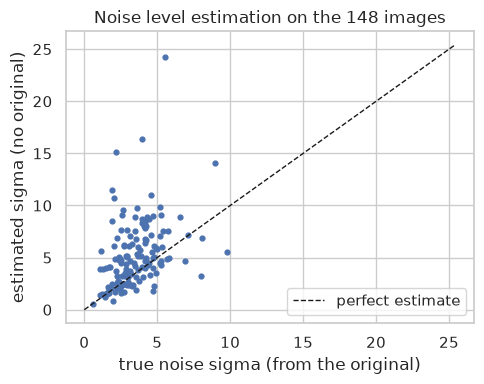

**Results.** True noise level of the 148 images (standard deviation of the difference, RGB): median **3.2**, maximum **9.8**; PSNR of the noisy images against their originals: median **38.1 dB** (from 28.4 to 52.5 dB). The noise is light: above 35 dB, a person barely sees it at normal viewing size. The blind estimate is only loosely related to the true level (r = 0.38), and on the **clean** originals it gives a median of 4.5, against 4.6 on the noisy files: at this noise level, the image textures weigh more in the estimate than the noise itself. Section 9.3 takes this into account.

In [9]:
print("Immerkaer kernel:\n", data._IMMERKAER.astype(int))
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(noisy_info["true_sigma"], noisy_info["noise_sigma"], s=12)
lim = max(noisy_info["true_sigma"].max(), noisy_info["noise_sigma"].max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1, label="perfect estimate")
ax.set_xlabel("true noise sigma (from the original)")
ax.set_ylabel("estimated sigma (no original)")
ax.set_title("Noise level estimation on the 148 images")
ax.legend()
plt.tight_layout()
plt.show()
corr = np.corrcoef(noisy_info["true_sigma"], noisy_info["noise_sigma"])[0, 1]
orig_estimate = np.median([data.estimate_noise(o) for o in originals])
display(Markdown(
    f"**Results.** True noise level of the 148 images (standard deviation of the difference, RGB): median "
    f"**{noisy_info['true_sigma'].median():.1f}**, maximum **{noisy_info['true_sigma'].max():.1f}**; PSNR of the noisy "
    f"images against their originals: median **{noisy_info['psnr_noisy'].median():.1f} dB** (from "
    f"{noisy_info['psnr_noisy'].min():.1f} to {noisy_info['psnr_noisy'].max():.1f} dB). The noise is light: above "
    "35 dB, a person barely sees it at normal viewing size. The blind estimate is only loosely related to the true "
    f"level (r = {corr:.2f}), and on the **clean** originals it gives a median of {orig_estimate:.1f}, against "
    f"{noisy_info['noise_sigma'].median():.1f} on the noisy files: at this noise level, the image textures weigh more "
    "in the estimate than the noise itself. Section 9.3 takes this into account."
))

## 4. Training data

An autoencoder learns denoising from pairs (noisy image, clean image). The models are trained in two steps:
first on many clean photos with the synthetic noise of section 3 (this gives a general colour denoiser), then
adapted with a small number of real TouNum pairs (section 9.2).

### 4.1 Clean photos with synthetic noise
- **Clean photos**: the photos of deliverable 1 (`Dataset Livrable 1 - Photo.zip`, already extracted and sampled
  there). The training split of deliverable 1 is used for training, its validation split for validation. Its test
  split stays unseen and is used in section 9.
- **Patches**: we cut 8 random 96×96 patches from each photo. The network is fully convolutional, so it learns on
  small patches and then works on images of any size. The photos keep their resolution (most are 640×480, like the
  TouNum images); only the few larger ones are reduced to 480 pixels on their short side. A first version trained
  on a CPU reduced every photo to 320 pixels, used 4 patches per photo and at most 25 epochs to keep training
  time reasonable. Training now runs on a GPU, so we keep the native resolution (closer to the images to denoise),
  take twice as many patches and let early stopping decide when to stop, up to 60 epochs.
- **Noise drawn on the fly**: in the training pipeline (`tf.data`), each patch gets a new noise level, a new noise
  and a random horizontal flip at every epoch. The validation noise is drawn once with a fixed seed so validation
  scores are comparable from one epoch (and one model) to the next.

In [10]:
meta = pd.read_csv(cls_config.CACHE_DIR / "meta.csv")
photos = meta[meta["source"] == cls_config.POSITIVE_CLASS]
photo_paths = {s: [cls_config.PROJECT_ROOT / p for p in photos.loc[photos["split"] == s, "path"]] for s in ("train", "val", "test")}
print({s: len(p) for s, p in photo_paths.items()}, "deliverable 1 photos per split")

t0 = time.perf_counter()
train_patches = data.cached_patches("train", photo_paths["train"])
val_patches = data.cached_patches("val", photo_paths["val"], crops_per_image=2, seed=config.SEED + 1)
if QUICK:
    train_patches, val_patches = train_patches[:640], val_patches[:128]
print(f"train patches {train_patches.shape}, val patches {val_patches.shape} ({time.perf_counter() - t0:.0f} s)")

train_ds = data.make_dataset(train_patches)
val_noisy, val_clean, val_sigma = data.fixed_noisy_set(val_patches)

{'train': 4200, 'val': 900, 'test': 900} deliverable 1 photos per split
train patches (33600, 96, 96, 3), val patches (1800, 96, 96, 3) (0 s)


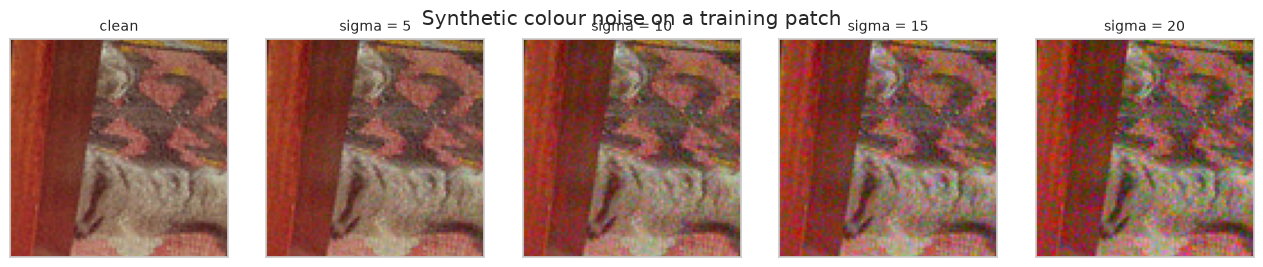

In [11]:
rng = np.random.default_rng(config.SEED)
example = train_patches[7]
cols = {"clean": [example]}
for s in (5, 10, 15, 20):
    cols[f"sigma = {s}"] = [data.add_noise(example, s, rng)]
evaluation.show_grid(cols, size=2.6)
plt.suptitle("Synthetic colour noise on a training patch", y=1.02)
plt.show()

### 4.2 Real pairs, and clean photos
The 148 (noisy, original) pairs are split once, at random with a fixed seed: 78 images to adapt the models
(fine-tuning), 20 to validate that step and choose the final model and decision rule, and **50 test images kept
aside** until the final measurement (section 9). From the fine-tuning and validation images we cut aligned 96×96
crops of the noisy image and of its original.

In production the denoiser will also receive clean photos. So the fine-tuning set gets as many crops of clean
photos (from the training split of deliverable 1), whose target is the input itself: the model has to learn to
remove the TouNum noise *and* to leave clean photos alone. The validation set mixes real and clean crops the same
way.

In [12]:
real_split = data.split_real_pairs(noisy_info["file"].tolist())
real_idx = {k: [int(np.flatnonzero(noisy_info["file"] == f)[0]) for f in files] for k, files in real_split.items()}
n_crops = 8 if QUICK else config.REAL_CROPS_PER_IMAGE
ft_noisy, ft_clean = data.pair_crops([noisy_images[i] for i in real_idx["finetune"]],
                                     [originals[i] for i in real_idx["finetune"]], n=n_crops)
rv_noisy, rv_clean = data.pair_crops([noisy_images[i] for i in real_idx["val"]],
                                     [originals[i] for i in real_idx["val"]], n=n_crops // 4, seed=config.SEED + 1)
n_clean_ft = 50 if QUICK else config.CLEAN_FT_PHOTOS
clean_ft = data.build_patches(photo_paths["train"][:n_clean_ft], crops_per_image=10)
clean_v = data.build_patches(photo_paths["val"][:n_clean_ft // 10], crops_per_image=6, seed=config.SEED + 2)
mix_noisy, mix_clean = np.concatenate([ft_noisy, clean_ft]), np.concatenate([ft_clean, clean_ft])
mix_val = (data.to_float(np.concatenate([rv_noisy, clean_v])), data.to_float(np.concatenate([rv_clean, clean_v])))
display(pd.DataFrame({"images": [len(real_split["finetune"]), n_clean_ft, len(real_split["val"]), n_clean_ft // 10,
                                 len(real_split["test"])],
                      "96x96 crops": [len(ft_noisy), len(clean_ft), len(rv_noisy), len(clean_v), 0]},
                     index=["fine-tuning, TouNum pairs", "fine-tuning, clean photos", "validation, TouNum pairs",
                            "validation, clean photos", "test, TouNum pairs"]))

,images,96x96 crops
"fine-tuning, TouNum pairs",78,9984
"fine-tuning, clean photos",1000,10000
"validation, TouNum pairs",20,640
"validation, clean photos",100,600
"test, TouNum pairs",50,0


## 5. Baseline: classical convolution filters

Before training anything we need a reference point. The simplest denoisers are **convolution filters**: each
output pixel is a weighted average of its neighbours, which averages out the noise but also blurs the edges.
- **Mean filter**: all pixels of a k×k window have the same weight.
- **Gaussian filter**: nearby pixels weigh more (Gaussian weights), so it blurs a little less for the same effect.
- **Median filter** (not a convolution): takes the median of the window, which keeps edges sharper and is very
  good against isolated outliers (salt-and-pepper noise).

In [13]:
print("3x3 mean kernel:\n", evaluation.mean_kernel(3).round(3))
print("Gaussian kernel, sigma = 1 (7x7):\n", evaluation.gaussian_kernel(1.0).round(3))

3x3 mean kernel:
 [[0.111 0.111 0.111]
 [0.111 0.111 0.111]
 [0.111 0.111 0.111]]
Gaussian kernel, sigma = 1 (7x7):
 [[0.    0.    0.001 0.002 0.001 0.    0.   ]
 [0.    0.003 0.013 0.022 0.013 0.003 0.   ]
 [0.001 0.013 0.059 0.097 0.059 0.013 0.001]
 [0.002 0.022 0.097 0.159 0.097 0.022 0.002]
 [0.001 0.013 0.059 0.097 0.059 0.013 0.001]
 [0.    0.003 0.013 0.022 0.013 0.003 0.   ]
 [0.    0.    0.001 0.002 0.001 0.    0.   ]]


In [14]:
def score(name, pred, clean=val_clean, sigma=val_sigma):
    """Per-patch PSNR / SSIM of a denoising method on the validation set."""
    return pd.DataFrame({"method": name, "sigma": sigma, "psnr": evaluation.psnr(clean, pred),
                         "ssim": evaluation.ssim(clean, pred)})


val_scores = [score("noisy (no filter)", val_noisy)]
for name, f in evaluation.CLASSICAL_FILTERS.items():
    val_scores.append(score(name, f(val_noisy)))
filter_table = pd.concat(val_scores).groupby("method", sort=False)[["psnr", "ssim"]].mean()
display(filter_table)
best_filter = filter_table.drop(index="noisy (no filter)")["psnr"].idxmax()

,psnr,ssim
method,,
noisy (no filter),27.101,0.644
mean 3x3,26.533,0.678
mean 5x5,25.373,0.626
Gaussian s=1,26.921,0.711
median 3x3,26.691,0.668
median 5x5,25.919,0.641


**PSNR** (peak signal-to-noise ratio, in dB) measures the pixel error against the clean image:
$\mathrm{PSNR} = 10 \log_{10}(1 / \mathrm{MSE})$ for pixels in [0, 1]. +3 dB means the squared error is halved.
**SSIM** (structural similarity, from 0 to 1) compares local brightness, contrast and structure, and is closer
to what a person perceives. Both are averaged over the validation patches, whose noise level is spread between 0
and 20. Note that the filters blur the brightness too, although the noise is only in the colours.

## 6. Convolutional autoencoders

An **autoencoder** is a network trained to output an image from an input image. The **encoder** compresses the
image into a smaller representation (fewer pixels, more channels), and the **decoder** rebuilds a full-size image
from it. For denoising, the input is the noisy image and the target is the clean one: the network has to learn
what belongs to the image and what is noise.

We compare three variants built by the same function:
1. **Plain convolutional autoencoder**: everything goes through the bottleneck, at a quarter of the resolution.
2. **Autoencoder with skip connections** (U-Net style): each encoder level is also passed directly to the
   decoder level of the same resolution. Fine details (edges, textures) no longer have to squeeze through the
   bottleneck, and the decoder can focus on removing the noise.
3. **Skip connections and residual output**: the last layer predicts the *noise* instead of the clean image, and
   the output is the input minus that noise (the idea of the DnCNN network). To leave a clean area unchanged, the
   network only has to predict zero; the two other variants have to rebuild every pixel, which always costs a
   little precision. This matters for the TouNum images, whose noise is light.

In [15]:
print(inspect.getsource(modeling.build_autoencoder))

def build_autoencoder(
    filters: tuple[int, ...] = (32, 64, 128),
    skips: bool = False,
    residual: bool = False,
    learning_rate: float = 1e-3,
    name: str | None = None,
) -> keras.Model:
    """Convolutional autoencoder that maps a noisy RGB image to a clean one (float32 in [0, 1]).

    Encoder: for each level, two Conv2D 3x3 + ReLU, then MaxPooling2D 2x2 (the last level is the bottleneck,
    without pooling). Decoder: Conv2DTranspose 2x2 stride 2 (upsampling) then two Conv2D 3x3, mirroring the
    encoder. Output: Conv2D 1x1 with 3 channels and a sigmoid.
    `skips=True` concatenates each encoder level with the decoder level of the same resolution (U-Net style),
    so fine details do not have to go through the low-resolution bottleneck.
    `residual=True` makes the last Conv2D 1x1 predict the noise instead of the clean image; the output is the noisy
    input minus that noise, clipped to [0, 1]. Leaving an image unchanged then only needs a prediction of zero.
    T

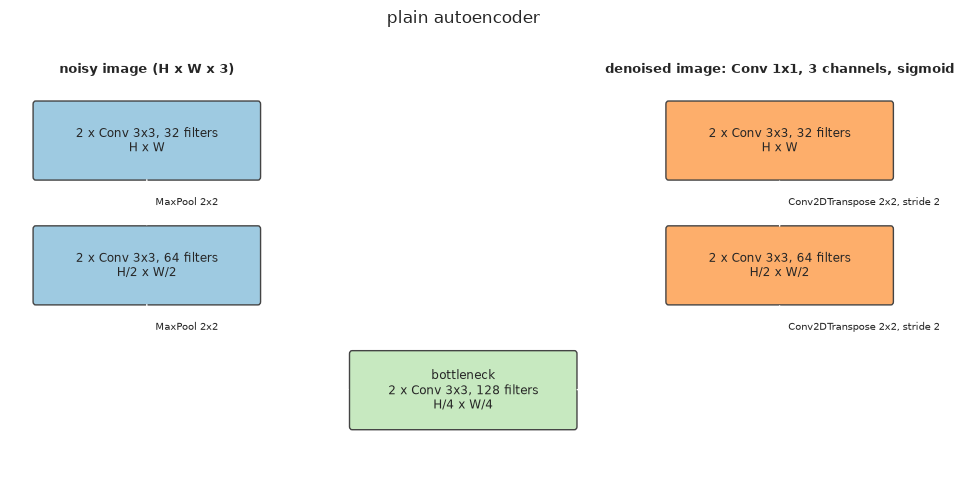

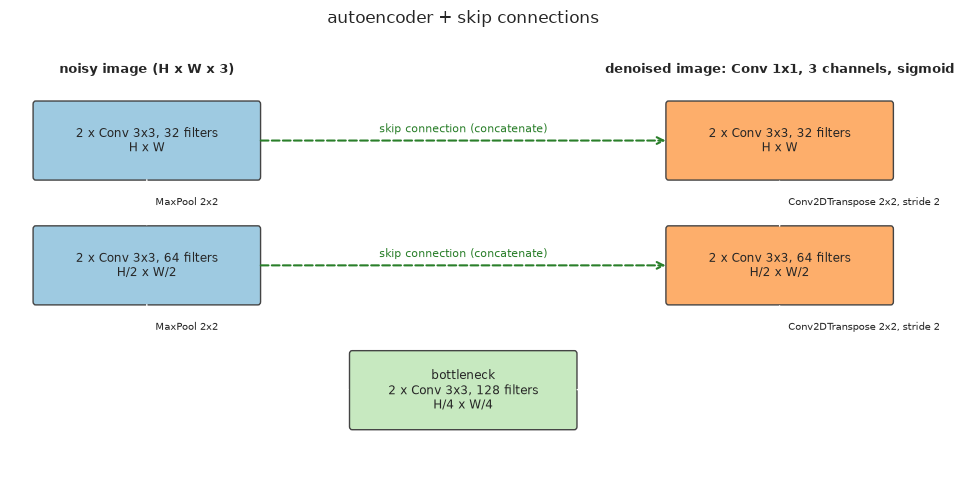

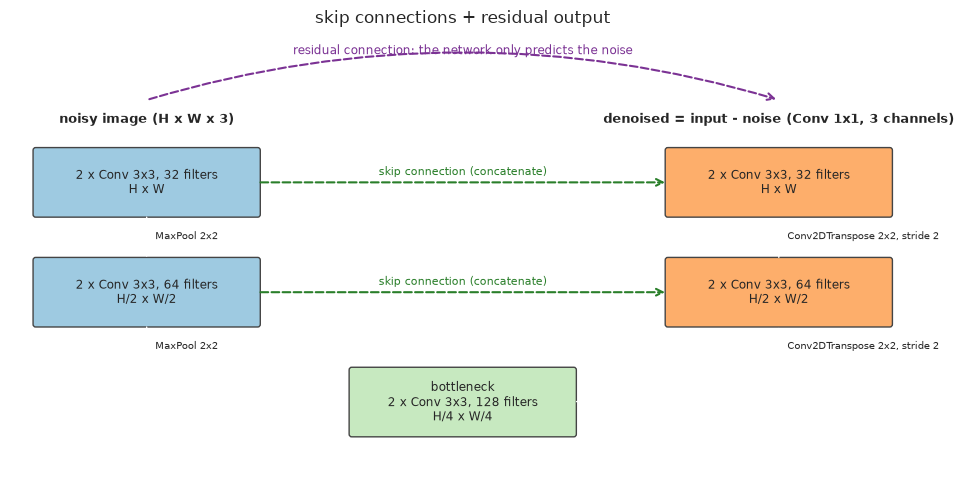

In [16]:
VARIANTS = {"plain autoencoder": dict(skips=False),
            "autoencoder + skip connections": dict(skips=True),
            "skip connections + residual output": dict(skips=True, residual=True)}
for name, kwargs in VARIANTS.items():
    evaluation.draw_autoencoder((32, 64, 128), title=name, **kwargs)
    plt.show()

In [17]:
keras.utils.set_random_seed(config.SEED)
modeling.build_autoencoder(skips=True, residual=True).summary()

Model: "residual_unet_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ noisy (InputLayer)  │ (None, None,      │          0 │ -                 │
│                     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv1 (Conv2D) │ (None, None,      │        896 │ noisy[0][0]       │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv2 (Conv2D) │ (None, None,      │      9,248 │ enc1_conv1[0][0]  │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_pool           │ (None, None,      │          0 │ enc1_conv2[0][0]  │
│ (MaxPooling2D)      │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv1 (Conv2D) │ (None, None,      │     18,496 │ enc1_pool[0][0]   │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv2 (Conv2D) │ (None, None,      │     36,928 │ enc2_conv1[0][0]  │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_pool           │ (None, None,      │          0 │ enc2_conv2[0][0]  │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv1    │ (None, None,      │     73,856 │ enc2_pool[0][0]   │
│ (Conv2D)            │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv2    │ (None, None,      │    147,584 │ bottleneck_conv1… │
│ (Conv2D)            │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec2_up             │ (None, None,      │     32,832 │ bottleneck_conv2… │
│ (Conv2DTranspose)   │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec2_skip           │ (None, None,      │          0 │ dec2_up[0][0],    │
│ (Concatenate)       │ None, 128)        │            │ enc2_conv2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec2_conv1 (Conv2D) │ (None, None,      │     73,792 │ dec2_skip[0][0]   │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec2_conv2 (Conv2D) │ (None, None,      │     36,928 │ dec2_conv1[0][0]  │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_up             │ (None, None,      │      8,224 │ dec2_conv2[0][0]  │
│ (Conv2DTranspose)   │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_skip           │ (None, None,      │          0 │ dec1_up[0][0],    │
│ (Concatenate)       │ None, 64)         │            │ enc1_conv2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_conv1 (Conv2D) │ (None, None,      │     18,464 │ dec1_skip[0][0]   │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_conv2 (Conv2D) │ (None, None,      │      9,248 │ dec1_conv1[0][0]

 Total params: 466,595 (1.78 MB)

 Trainable params: 466,595 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

### 6.1 Parameters, loss and optimiser

| Item | Choice | Why |
|---|---|---|
| Input / output | RGB image, float values in [0, 1], any size (multiple of 4) | fully convolutional, no dense layer |
| Convolutions | 3×3, ReLU, `same` padding, 32 / 64 / 128 filters | standard building block; the receptive field grows at each level |
| Downsampling / upsampling | MaxPooling 2×2 / Conv2DTranspose 2×2 stride 2 | halves / doubles the resolution, the transposed convolution learns how to upsample |
| Output | Conv 1×1, 3 channels, sigmoid; for the residual variant, Conv 1×1 predicting the noise, subtracted from the input and clipped to [0, 1] | keeps the pixels in [0, 1] |
| **Loss** | **mean squared error** $\frac{1}{N}\sum (\hat{x} - x)^2$ between output and clean image | directly linked to PSNR, which is what we want to raise |
| **Optimiser** | **Adam**, learning rate $10^{-3}$, batches of 32 patches | reliable default, no learning rate tuning needed |
| Regularisation | early stopping (patience 6) on the validation loss, best weights restored | stops when validation stops improving |
| Tracked metrics | PSNR and SSIM | the quality measures defined in section 5 |

The three models have about the same number of parameters (about 420k for the plain one, 467k for the two
others): the skip connections only add channels to the first convolution of each decoder level, and the residual
output has the same size as the sigmoid output.

## 7. Training and learning curves

In [18]:
histories, models_, times = {}, {}, {}
for name, kwargs in VARIANTS.items():
    keras.utils.set_random_seed(config.SEED)
    model = modeling.build_autoencoder(**kwargs)
    t0 = time.perf_counter()
    histories[name] = modeling.train(model, train_ds, (val_noisy, val_clean), epochs=EPOCHS, patience=6, verbose=0)
    times[name] = time.perf_counter() - t0
    models_[name] = model
    print(f"{name}: {len(histories[name])} epochs in {times[name] / 60:.1f} min")

plain autoencoder: 43 epochs in 4.9 min


autoencoder + skip connections: 30 epochs in 3.4 min


skip connections + residual output: 37 epochs in 4.1 min


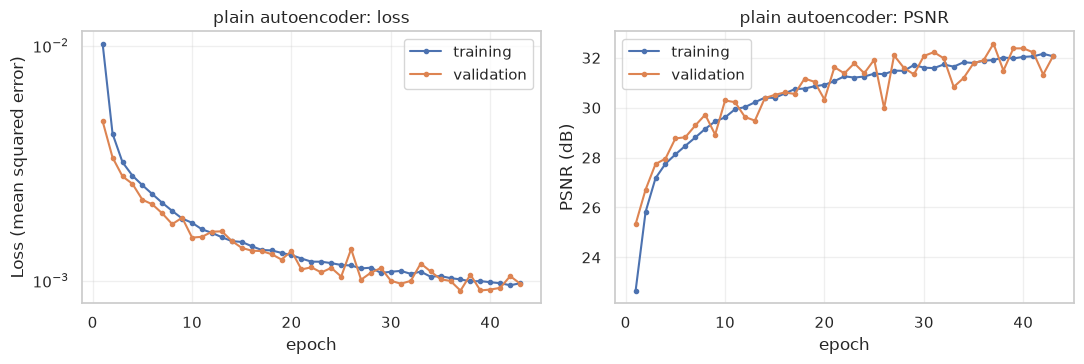

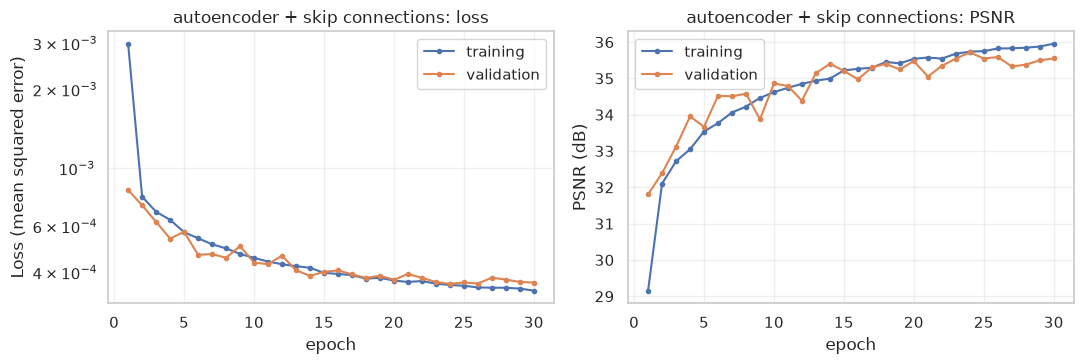

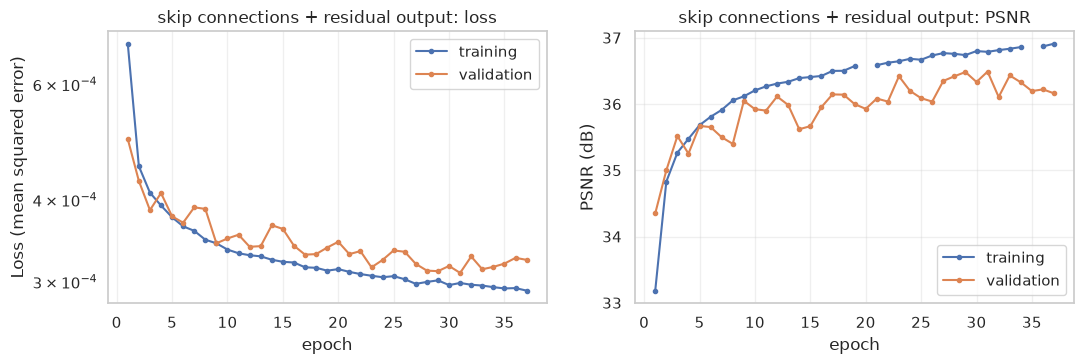

In [19]:
for name, hist in histories.items():
    evaluation.plot_history(hist, name)
    plt.show()

In [20]:
rows = []
for name, hist in histories.items():
    best = hist.loc[hist["val_loss"].idxmin()]
    rows.append({"model": name, "parameters": models_[name].count_params(), "epochs run": len(hist),
                 "best epoch": int(best["epoch"]), "train PSNR": best["psnr"], "val PSNR": best["val_psnr"],
                 "val SSIM": best["val_ssim"], "train - val PSNR gap": best["psnr"] - best["val_psnr"],
                 "time (min)": times[name] / 60})
train_table = pd.DataFrame(rows).set_index("model")
display(train_table)
chosen = train_table["val PSNR"].idxmax()
gap = train_table.loc[chosen, "train - val PSNR gap"]
display(Markdown(
    f"**Results.** Best validation PSNR on synthetic noise: **{chosen}** with "
    f"**{train_table.loc[chosen, 'val PSNR']:.2f} dB** (SSIM {train_table.loc[chosen, 'val SSIM']:.3f}), against "
    + ", ".join(f"{train_table.loc[n, 'val PSNR']:.2f} dB for the {n}" for n in train_table.index if n != chosen)
    + f" and {filter_table.loc[best_filter, 'psnr']:.2f} dB for the best classical filter ({best_filter}). "
    f"The training and validation PSNR of this model differ by {gap:+.2f} dB"
    + (": no sign of overfitting, the model could probably use more capacity or more epochs (bias side)."
       if abs(gap) < 0.5 else
       (": training is clearly better than validation, a sign of overfitting (variance side)." if gap > 0
        else ": validation is better than training. Training PSNR is averaged over the epoch while the weights "
             "are still changing, and the training noise is redrawn at every epoch, so this is not a problem."))
))

,parameters,epochs run,best epoch,train PSNR,val PSNR,val SSIM,train - val PSNR gap,time (min)
model,,,,,,,,
plain autoencoder,420515,43,37,31.911,32.567,0.912,-0.655,4.851
autoencoder + skip connections,466595,30,24,35.736,35.718,0.949,0.018,3.377
skip connections + residual output,466595,37,31,36.787,36.489,0.956,0.298,4.138


**Results.** Best validation PSNR on synthetic noise: **skip connections + residual output** with **36.49 dB** (SSIM 0.956), against 32.57 dB for the plain autoencoder, 35.72 dB for the autoencoder + skip connections and 26.92 dB for the best classical filter (Gaussian s=1). The training and validation PSNR of this model differ by +0.30 dB: no sign of overfitting, the model could probably use more capacity or more epochs (bias side).

**Reading the curves.** The training noise is new at every epoch, so the network cannot memorise noisy patches:
every patch comes back with a different noise, overfitting is unlikely and the train and validation curves stay
close. If a gap appeared, the usual remedies would be more photos, more augmentation (rotations, colour changes)
or weight decay. A plain autoencoder has to squeeze everything through its bottleneck, at a quarter of the
resolution, so it tends to lose fine detail: a bias problem that more data would not fix, and that skip
connections are meant to remove. The cell below checks this on our runs.

In [21]:
plain, skip = train_table.loc["plain autoencoder"], train_table.loc["autoencoder + skip connections"]
display(Markdown(
    f"**Results.** At their best epoch, the plain autoencoder reaches {plain['train PSNR']:.2f} dB on training and "
    f"{plain['val PSNR']:.2f} dB on validation; with skip connections, {skip['train PSNR']:.2f} dB and "
    f"{skip['val PSNR']:.2f} dB. "
    + ("The plain autoencoder levels off lower on both sets, which is the bias problem described above."
       if plain["val PSNR"] < skip["val PSNR"] and plain["train PSNR"] < skip["train PSNR"] else
       "In this run the plain autoencoder does not level off lower than the version with skip connections, so the "
       "bottleneck is not what limits it.")
))

**Results.** At their best epoch, the plain autoencoder reaches 31.91 dB on training and 32.57 dB on validation; with skip connections, 35.74 dB and 35.72 dB. The plain autoencoder levels off lower on both sets, which is the bias problem described above.

## 8. Evaluation by noise level

Denoising is easy when there is little noise and hard when there is a lot, so a single average hides a lot. We
now add noise at fixed levels to the validation patches and compare every method at each level. Level 0 checks
that a clean image is not damaged. Here the PSNR is computed from the mean squared error over all patches: some
flat patches (pure white) come out of the JPEG step unchanged at level 0, and their own PSNR would be infinite.

sigma,0,5,10,15,20
method,,,,,
Gaussian s=1,25.84,25.62,25.06,24.29,23.43
autoencoder + skip connections,37.23,35.77,34.43,33.45,32.45
noisy (no filter),40.33,30.47,25.29,22.11,19.84
plain autoencoder,30.90,30.80,30.52,30.15,29.68
skip connections + residual output,39.08,36.70,35.05,33.94,32.89


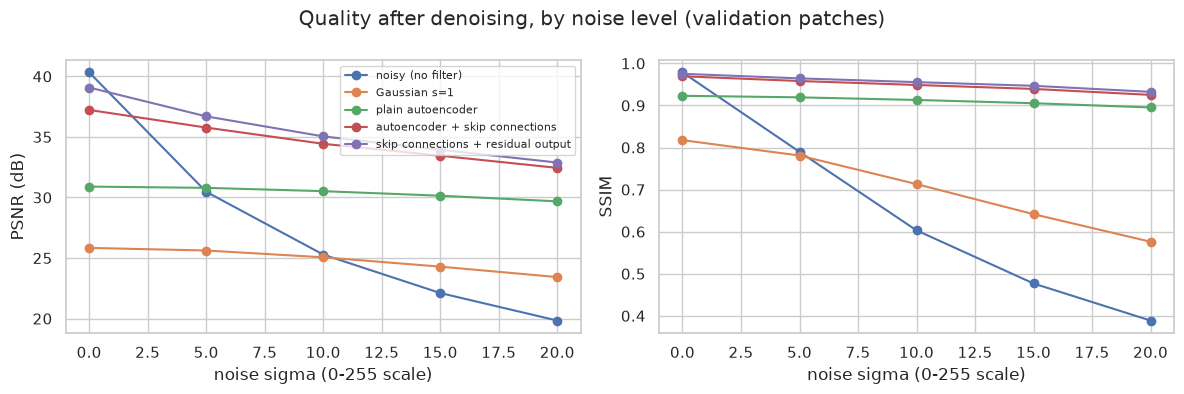

In [22]:
def all_methods(noisy):
    """Outputs of every method on a batch of noisy float patches."""
    outs = {"noisy (no filter)": noisy, best_filter: evaluation.CLASSICAL_FILTERS[best_filter](noisy)}
    for name, model in models_.items():
        outs[name] = modeling.predict(model, noisy)
    return outs


level_rows, level_examples = [], {}
for s in config.SIGMA_LEVELS:
    rng = np.random.default_rng(config.SEED + s)
    noisy = data.to_float(np.stack([data.add_noise(p, s, rng) for p in val_patches]))
    for name, out in all_methods(noisy).items():
        level_rows.append({"sigma": s, "method": name, "PSNR": evaluation.dataset_psnr(val_clean, out),
                           "SSIM": evaluation.ssim(val_clean, out).mean()})
        level_examples[(s, name)] = out[11]
level_df = pd.DataFrame(level_rows)
display(level_df.pivot(index="method", columns="sigma", values="PSNR").round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, grp in level_df.groupby("method", sort=False):
    axes[0].plot(grp["sigma"], grp["PSNR"], marker="o", label=name)
    axes[1].plot(grp["sigma"], grp["SSIM"], marker="o", label=name)
axes[0].set_ylabel("PSNR (dB)")
axes[1].set_ylabel("SSIM")
for ax in axes:
    ax.set_xlabel("noise sigma (0-255 scale)")
axes[0].legend(fontsize=8)
plt.suptitle("Quality after denoising, by noise level (validation patches)")
plt.tight_layout()
plt.show()

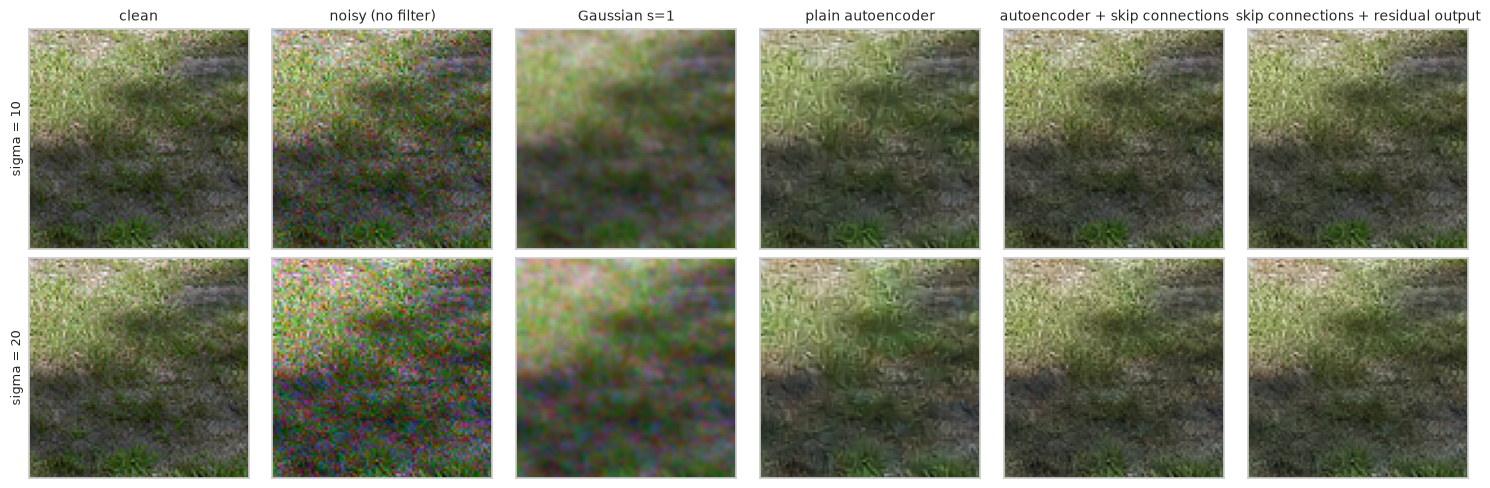

In [23]:
methods = list(all_methods(val_noisy[:1]).keys())
cols = {"clean": [val_patches[11]] * 2}
for name in methods:
    cols[name] = [level_examples[(10, name)], level_examples[(20, name)]]
evaluation.show_grid(cols, ["sigma = 10", "sigma = 20"], size=2.5)
plt.show()

In [24]:
pivot = level_df.pivot(index="method", columns="sigma", values="PSNR")
gain = pivot.loc[chosen] - pivot.loc["noisy (no filter)"]
display(Markdown(
    f"**Results.** Gain of the {chosen} over the noisy input: "
    + ", ".join(f"{gain[s]:+.1f} dB at sigma {s}" for s in config.SIGMA_LEVELS) + ". "
    f"The best classical filter ({best_filter}) gives "
    + ", ".join(f"{pivot.loc[best_filter, s] - pivot.loc['noisy (no filter)', s]:+.1f} dB" for s in config.SIGMA_LEVELS)
    + ". "
    + ("On clean images (sigma 0) the autoencoder costs a little quality: like any denoiser, it slightly changes "
       "images that had nothing to remove. This is why section 9.3 decides when to apply it."
       if gain[0] < 0 else "Even on clean images (sigma 0) the autoencoder does not lower the quality.")
))

**Results.** Gain of the skip connections + residual output over the noisy input: -1.2 dB at sigma 0, +6.2 dB at sigma 5, +9.8 dB at sigma 10, +11.8 dB at sigma 15, +13.0 dB at sigma 20. The best classical filter (Gaussian s=1) gives -14.5 dB, -4.8 dB, -0.2 dB, +2.2 dB, +3.6 dB. On clean images (sigma 0) the autoencoder costs a little quality: like any denoiser, it slightly changes images that had nothing to remove. This is why section 9.3 decides when to apply it.

## 9. Case study

### 9.1 The real TouNum images, with models trained on synthetic noise
This is the real test: the 50 test images of section 4.2, with the real noise, scored against their clean
originals. Each image is denoised at full size (the network is fully convolutional). We also pass the clean
originals themselves through each network, to see how much a network changes an image that has no noise.

In [25]:
test_idx = real_idx["test"]
test_noisy = [noisy_images[i] for i in test_idx]
test_orig = [originals[i] for i in test_idx]


def real_scores(outputs, refs=test_orig):
    """Per-image PSNR and SSIM of a list of uint8 outputs against their clean originals."""
    return (np.array([evaluation.psnr(data.to_float(o), data.to_float(x)) for o, x in zip(refs, outputs)]),
            np.array([evaluation.ssim(data.to_float(o), data.to_float(x)) for o, x in zip(refs, outputs)]))


filtered = [data.to_uint8(evaluation.CLASSICAL_FILTERS[best_filter](data.to_float(img))) for img in test_noisy]
case_rows = {"noisy (no filter)": real_scores(test_noisy), best_filter: real_scores(filtered)}
clean_change = {}
t0 = time.perf_counter()
for name, model in models_.items():
    case_rows[name] = real_scores([modeling.denoise(model, img) for img in test_noisy])
    clean_change[name] = real_scores([modeling.denoise(model, img) for img in test_orig])[0].mean()
synth_table = pd.DataFrame({name: {"PSNR": p.mean(), "SSIM": s.mean(),
                                   "images improved": (p > case_rows["noisy (no filter)"][0]).mean()}
                            for name, (p, s) in case_rows.items()}).T
synth_table["PSNR on a clean original"] = pd.Series(clean_change)
display(synth_table)
print(f"{len(test_noisy)} test images, {len(models_)} models, in {time.perf_counter() - t0:.0f} s")

,PSNR,SSIM,images improved,PSNR on a clean original
noisy (no filter),38.072,0.967,0.0,NaN
Gaussian s=1,28.055,0.823,0.0,NaN
plain autoencoder,33.067,0.926,0.0,33.227
autoencoder + skip connections,36.949,0.963,0.0,39.882
skip connections + residual output,37.372,0.964,0.0,41.854


50 test images, 3 models, in 8 s


In [26]:
base = synth_table.loc["noisy (no filter)", "PSNR"]
best_synth = synth_table.drop(index=["noisy (no filter)", best_filter])["PSNR"].idxmax()
display(Markdown(
    f"**Results.** On the 50 real test images, the noisy files are at **{base:.2f} dB**. The best model trained on "
    f"synthetic noise ({best_synth}) gives **{synth_table.loc[best_synth, 'PSNR']:.2f} dB** and improves "
    f"{synth_table.loc[best_synth, 'images improved']:.0%} of the images; the best classical filter gives "
    f"{synth_table.loc[best_filter, 'PSNR']:.2f} dB. On a clean original, the networks give "
    + ", ".join(f"{clean_change[n]:.1f} dB ({n})" for n in models_)
    + ": even without noise, their output is not exactly the input. "
    + ("Since the real noise is light, this error is of the same order as the noise itself, and a model trained "
       "on synthetic noise alone does not help on the real images."
       if synth_table.loc[best_synth, "PSNR"] < base + 0.3 else
       "The synthetic training already helps on the real images.")
))

**Results.** On the 50 real test images, the noisy files are at **38.07 dB**. The best model trained on synthetic noise (skip connections + residual output) gives **37.37 dB** and improves 0% of the images; the best classical filter gives 28.05 dB. On a clean original, the networks give 33.2 dB (plain autoencoder), 39.9 dB (autoencoder + skip connections), 41.9 dB (skip connections + residual output): even without noise, their output is not exactly the input. Since the real noise is light, this error is of the same order as the noise itself, and a model trained on synthetic noise alone does not help on the real images.

Two things can limit models trained on synthetic noise, both visible in section 3: the real noise is very light
(around 38 dB), so the small error any network makes on clean areas weighs a lot, and it is not exactly our
synthetic noise (loss of saturation, stronger noise on saturated colours). The residual output addresses the
first point. For the second, we use the real pairs.

### 9.2 Fine-tuning on real pairs
Each model trained on synthetic noise is trained again on the fine-tuning set of section 4.2 (crops of the 78
TouNum images and as many crops of clean photos), starting from its current weights, with a learning rate ten
times lower so that it adapts without forgetting what it learned. Early stopping watches the validation crops.
The 50 test images are still unseen. To show what the clean photos bring, the residual model is also fine-tuned
on the TouNum pairs alone.

Besides the PSNR on the 50 noisy test images, the table measures how much each model changes **clean** photos
(50 photos of the deliverable 1 test split): the PSNR of the output against the input, where higher means the
photo is left closer to how it was.

Fine-tuning of 4 models in 18.1 min


,val PSNR (mixed crops)
plain autoencoder,35.328
autoencoder + skip connections,43.972
skip connections + residual output,55.810


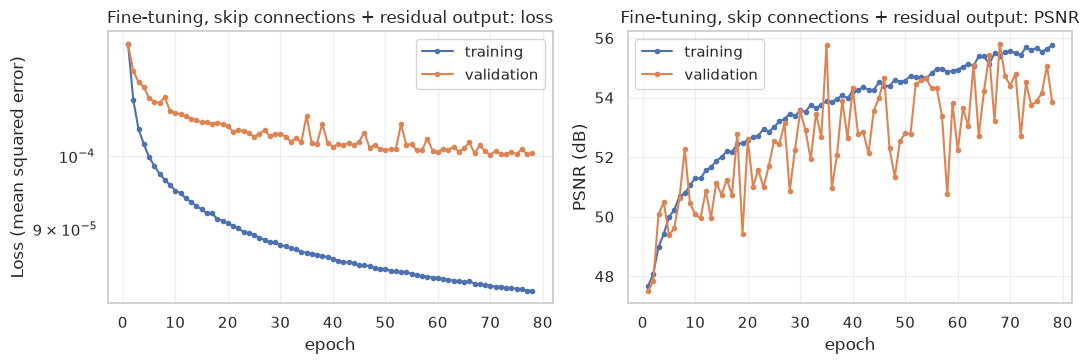

In [27]:
def fine_tuned(model, noisy_crops, clean_crops, val):
    """Copy of `model` (the synthetic version is kept for the comparison), fine-tuned on the given crops."""
    keras.utils.set_random_seed(config.SEED)
    tuned = keras.models.clone_model(model)
    tuned.set_weights(model.get_weights())
    hist = modeling.fine_tune(tuned, data.make_pair_dataset(noisy_crops, clean_crops), val, epochs=FT_EPOCHS, verbose=0)
    return tuned, hist


ft_models, ft_histories = {}, {}
t0 = time.perf_counter()
for name, model in models_.items():
    ft_models[name], ft_histories[name] = fine_tuned(model, mix_noisy, mix_clean, mix_val)
residual_name = "skip connections + residual output"
real_only, _ = fine_tuned(models_[residual_name], ft_noisy, ft_clean, (data.to_float(rv_noisy), data.to_float(rv_clean)))
print(f"Fine-tuning of {len(ft_models) + 1} models in {(time.perf_counter() - t0) / 60:.1f} min")
ft_val = pd.Series({name: hist["val_psnr"].max() for name, hist in ft_histories.items()}, name="val PSNR (mixed crops)")
display(ft_val.to_frame())
final_name = ft_val.idxmax()
denoiser = ft_models[final_name]
evaluation.plot_history(ft_histories[final_name], f"Fine-tuning, {final_name}")
plt.show()

In [28]:
clean_test = [cls_data.read_rgb(p) for p in photo_paths["test"][:10 if QUICK else 50]]


def clean_psnr(model):
    """How much a model changes clean photos: PSNR of the output against the input, over all the photos."""
    mse = np.mean([np.mean((modeling.denoise(model, c).astype(np.float64) - c) ** 2) for c in clean_test])
    return 10 * np.log10(255**2 / mse)


clean_cols = {name: clean_psnr(model) for name, model in models_.items()}
for name, model in ft_models.items():
    case_rows[f"{name}, fine-tuned"] = real_scores([modeling.denoise(model, img) for img in test_noisy])
    clean_cols[f"{name}, fine-tuned"] = clean_psnr(model)
case_rows[f"{residual_name}, fine-tuned on TouNum pairs only"] = real_scores([modeling.denoise(real_only, img) for img in test_noisy])
clean_cols[f"{residual_name}, fine-tuned on TouNum pairs only"] = clean_psnr(real_only)
case = pd.DataFrame({name: {"PSNR": p.mean(), "SSIM": s.mean(), "images improved": (p > case_rows["noisy (no filter)"][0]).mean()}
                     for name, (p, s) in case_rows.items()}).T
case["PSNR on clean photos (output vs input)"] = pd.Series(clean_cols)
display(case)
final_psnr = case_rows[f"{final_name}, fine-tuned"][0]
final_gain = final_psnr - case_rows["noisy (no filter)"][0]
denoised_test = [modeling.denoise(denoiser, img) for img in test_noisy]

,PSNR,SSIM,images improved,PSNR on clean photos (output vs input)
noisy (no filter),38.072,0.967,0.00,NaN
Gaussian s=1,28.055,0.823,0.00,NaN
plain autoencoder,33.067,0.926,0.00,30.537
autoencoder + skip connections,36.949,0.963,0.00,38.715
skip connections + residual output,37.372,0.964,0.00,41.413
"plain autoencoder, fine-tuned",34.489,0.942,0.00,32.057
"autoencoder + skip connections, fine-tuned",38.559,0.968,0.86,46.557
"skip connections + residual output, fine-tuned",39.035,0.970,0.96,55.177
"skip connections + residual output, fine-tuned on TouNum pairs only",39.062,0.970,0.96,36.083


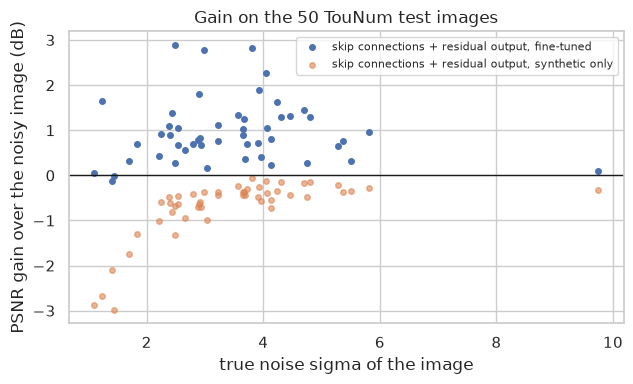

In [29]:
fig, ax = plt.subplots(figsize=(6.5, 4))
true_sigma = noisy_info.loc[test_idx, "true_sigma"].to_numpy()
ax.scatter(true_sigma, final_gain, s=16, label=f"{final_name}, fine-tuned")
ax.scatter(true_sigma, case_rows[best_synth][0] - case_rows["noisy (no filter)"][0], s=16, alpha=0.6,
           label=f"{best_synth}, synthetic only")
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("true noise sigma of the image")
ax.set_ylabel("PSNR gain over the noisy image (dB)")
ax.set_title("Gain on the 50 TouNum test images")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

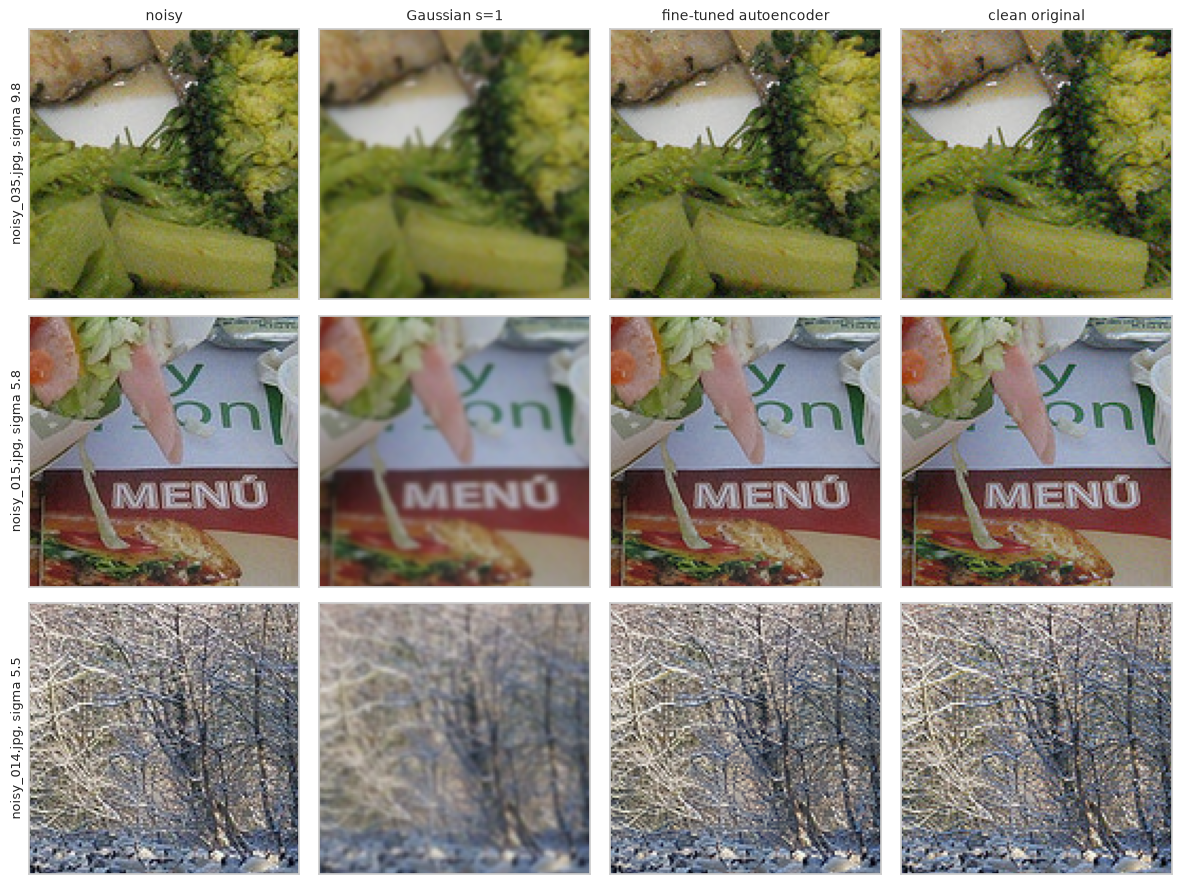

In [30]:
show = list(np.argsort(-true_sigma)[:3])
evaluation.show_grid({
    "noisy": [center_crop(test_noisy[k], 128) for k in show],
    best_filter: [center_crop(filtered[k], 128) for k in show],
    "fine-tuned autoencoder": [center_crop(denoised_test[k], 128) for k in show],
    "clean original": [center_crop(test_orig[k], 128) for k in show],
}, [f"{noisy_info.file[test_idx[k]]}, sigma {true_sigma[k]:.1f}" for k in show], size=3)
plt.show()

In [31]:
ablation = case.loc[f"{residual_name}, fine-tuned on TouNum pairs only"]
final_row = case.loc[f"{final_name}, fine-tuned"]
display(Markdown(
    f"**Results.** Selected on the validation crops: **{final_name}**, fine-tuned (validation PSNR "
    f"{ft_val[final_name]:.2f} dB). On the 50 test images it brings the mean PSNR from "
    f"**{case_rows['noisy (no filter)'][0].mean():.2f}** to **{final_psnr.mean():.2f} dB** ({final_gain.mean():+.2f} dB) "
    f"and improves **{(final_gain > 0).mean():.0%}** of the images, against {synth_table.loc[best_synth, 'PSNR']:.2f} dB "
    f"for the best model trained on synthetic noise only. Fine-tuned versions of the other variants: "
    + ", ".join(f"{n} {case.loc[f'{n}, fine-tuned', 'PSNR']:.2f} dB" for n in ft_models if n != final_name) + ". "
    f"On clean photos the selected model gives {final_row['PSNR on clean photos (output vs input)']:.1f} dB. "
    f"Fine-tuned on the TouNum pairs alone, the residual model reaches {ablation['PSNR']:.2f} dB on the noisy test "
    f"images but only {ablation['PSNR on clean photos (output vs input)']:.1f} dB on clean photos: without clean "
    "photos in the fine-tuning set, it also changes images that had no noise."
))

**Results.** Selected on the validation crops: **skip connections + residual output**, fine-tuned (validation PSNR 55.81 dB). On the 50 test images it brings the mean PSNR from **38.07** to **39.03 dB** (+0.96 dB) and improves **96%** of the images, against 37.37 dB for the best model trained on synthetic noise only. Fine-tuned versions of the other variants: plain autoencoder 34.49 dB, autoencoder + skip connections 38.56 dB. On clean photos the selected model gives 55.2 dB. Fine-tuned on the TouNum pairs alone, the residual model reaches 39.06 dB on the noisy test images but only 36.1 dB on clean photos: without clean photos in the fine-tuning set, it also changes images that had no noise.

### 9.3 When should the pipeline denoise?
A denoiser cannot add information: on an image that is already clean it can only change details. In production
the pipeline does not know which photos are noisy. Section 3.3 showed that the blind estimate is a weak signal at
this noise level, so instead of assuming a threshold we let the validation data decide between "never denoise",
"always denoise" and "denoise when the estimate is at least t", for every value of t.

The validation set mixes the 20 real validation images (noisy) and 20 clean photos from the validation split of
deliverable 1, so we weigh noisy and clean photos equally (TouNum did not tell us the share of noisy photos in
their archives). For each image the gain is the decrease of the mean squared error against the clean version,
which is defined for clean images too. The rule kept is the one with the largest mean gain.

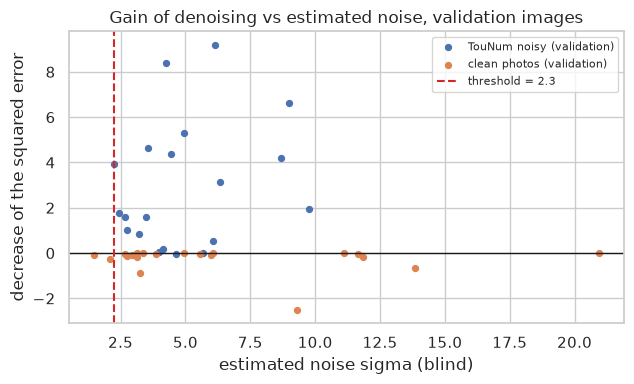

In [32]:
def mse_gain(noisy, clean):
    """Decrease of the mean squared error (0-255 scale) obtained by denoising one image."""
    before = np.mean((noisy.astype(np.float32) - clean) ** 2)
    after = np.mean((modeling.denoise(denoiser, noisy).astype(np.float32) - clean) ** 2)
    return before - after


def rule_table(noisy_list, clean_list):
    est = np.array([data.estimate_noise(img) for img in noisy_list])
    gains = np.array([mse_gain(n, c) for n, c in zip(noisy_list, clean_list)])
    return est, gains


n_clean = 5 if QUICK else 20
clean_val = [cls_data.read_rgb(p) for p in photo_paths["val"][:n_clean]]
val_est, val_gain = rule_table([noisy_images[i] for i in real_idx["val"]] + clean_val,
                               [originals[i] for i in real_idx["val"]] + clean_val)
candidates = np.concatenate([[0.0], np.sort(val_est), [np.inf]])
mean_gain = [np.where(val_est >= t, val_gain, 0).mean() for t in candidates]
NOISE_THRESHOLD = float(candidates[int(np.argmax(mean_gain))])
is_noisy_val = np.arange(len(val_est)) < len(real_idx["val"])

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(val_est[is_noisy_val], val_gain[is_noisy_val], s=18, label="TouNum noisy (validation)")
ax.scatter(val_est[~is_noisy_val], val_gain[~is_noisy_val], s=18, label="clean photos (validation)")
ax.axhline(0, color="k", lw=1)
if np.isfinite(NOISE_THRESHOLD) and NOISE_THRESHOLD > 0:
    ax.axvline(NOISE_THRESHOLD, color="tab:red", ls="--", label=f"threshold = {NOISE_THRESHOLD:.1f}")
ax.set_xlabel("estimated noise sigma (blind)")
ax.set_ylabel("decrease of the squared error")
ax.set_title("Gain of denoising vs estimated noise, validation images")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [33]:
test_est, test_gain = rule_table(test_noisy + clean_test, test_orig + clean_test)
is_noisy_test = np.arange(len(test_est)) < len(test_noisy)
apply = test_est >= NOISE_THRESHOLD
rule_name = ("always denoise" if NOISE_THRESHOLD == 0 else "never denoise" if not np.isfinite(NOISE_THRESHOLD)
             else f"denoise when the estimate is at least {NOISE_THRESHOLD:.1f}")
display(Markdown(
    f"**Results.** Rule chosen on the validation images: **{rule_name}**. On the test images "
    f"({is_noisy_test.sum()} TouNum noisy images and {(~is_noisy_test).sum()} clean photos from the test split of "
    f"deliverable 1), the mean decrease of the squared error is {np.where(apply, test_gain, 0).mean():+.2f} with the "
    f"rule, {test_gain.mean():+.2f} when always denoising and 0 when never denoising. The rule denoises "
    f"{apply[is_noisy_test].mean():.0%} of the noisy images and {apply[~is_noisy_test].mean():.0%} of the clean ones; "
    f"denoising makes {(test_gain[~is_noisy_test] < 0).mean():.0%} of the clean photos slightly worse, with a mean "
    f"change of {test_gain[~is_noisy_test].mean():+.2f}, against {test_gain[is_noisy_test].mean():+.2f} on the noisy ones."
))

**Results.** Rule chosen on the validation images: **denoise when the estimate is at least 2.3**. On the test images (50 TouNum noisy images and 50 clean photos from the test split of deliverable 1), the mean decrease of the squared error is +1.08 with the rule, +1.14 when always denoising and 0 when never denoising. The rule denoises 84% of the noisy images and 76% of the clean ones; denoising makes 96% of the clean photos slightly worse, with a mean change of -0.20, against +2.48 on the noisy ones.

### 9.4 Does noise hurt the photo filter of deliverable 1?
The pipeline classifies images **before** denoising them (only photos are denoised). So the photo filter must
itself cope with noisy inputs. We take the test split of deliverable 1 (photos and non-photos never used here),
add synthetic colour noise at increasing levels, and measure the accuracy of the production classifier saved by
deliverable 1, with and without denoising first. To keep this fast, we use 60 images per type and downscale
them so their short side is 320 pixels before adding the noise.

In [34]:
classifier_path = cls_config.MODELS_DIR / "photo_classifier.keras"
if QUICK and not classifier_path.exists():          # deliverable 1 only ran in quick mode
    classifier_path = Path(tempfile.gettempdir()) / "tounum_quick" / "photo_classifier.keras"
classifier = keras.models.load_model(classifier_path)
test_meta = meta[meta["split"] == "test"].groupby("source").sample(n=10 if QUICK else 60, random_state=config.SEED)
test_full = [data.downscale(cls_data.read_rgb(cls_config.PROJECT_ROOT / p), 320) for p in test_meta["path"]]
labels = test_meta["label"].to_numpy()

acc_rows = []
for s in (0, 10, 20):
    rng = np.random.default_rng(config.SEED + 100 + s)
    noisy_set = [data.add_noise(img, s, rng) if s else img for img in test_full]
    for variant, imgs in (("noisy", noisy_set), ("denoised first", [modeling.denoise(denoiser, im) for im in noisy_set])):
        proba = cls_modeling.predict_proba(classifier, np.stack([cls_data.resize(im) for im in imgs]))
        pred = proba >= 0.5
        acc_rows.append({"sigma": s, "input": variant, "accuracy": (pred == labels).mean(),
                         "photos kept": pred[labels == 1].mean(), "non-photos rejected": (~pred[labels == 0]).mean()})
acc_df = pd.DataFrame(acc_rows)
display(acc_df.pivot(index="input", columns="sigma", values="accuracy").round(3))

sigma,0,10,20
input,,,
denoised first,0.967,0.947,0.943
noisy,0.967,0.947,0.943


In [35]:
top = acc_df["sigma"].max()
acc0 = acc_df.query("sigma == 0 and input == 'noisy'")["accuracy"].iloc[0]
acc_top = acc_df.query("sigma == @top and input == 'noisy'")["accuracy"].iloc[0]
acc_top_d = acc_df.query("sigma == @top and input == 'denoised first'")["accuracy"].iloc[0]
display(Markdown(
    f"**Results.** On {len(labels)} test images ({labels.sum()} photos), the classifier accuracy goes from "
    f"**{acc0:.3f}** on the original images to **{acc_top:.3f}** at sigma {top}, and to **{acc_top_d:.3f}** at sigma "
    f"{top} when the images are denoised first. "
    + ("The photo filter barely notices the noise: images are shrunk to 128×128 before classification, and the "
       "shrinking averages most of the noise away. Classifying before denoising is therefore safe."
       if acc0 - acc_top < 0.03 else
       "Strong noise does hurt the photo filter. For very noisy archives it would be worth denoising every image "
       "before classifying it, or training the classifier with noise augmentation.")
))

**Results.** On 300 test images (60 photos), the classifier accuracy goes from **0.967** on the original images to **0.943** at sigma 20, and to **0.943** at sigma 20 when the images are denoised first. The photo filter barely notices the noise: images are shrunk to 128×128 before classification, and the shrinking averages most of the noise away. Classifying before denoising is therefore safe.

### 9.5 Saving the denoiser
The settings file keeps the decision rule and the names of the 50 test images, so that deliverable 3 can measure
captions on TouNum images the denoiser never saw.

In [36]:
SAVE_DIR = Path(tempfile.gettempdir()) / "tounum_quick" if QUICK else config.MODELS_DIR
SAVE_DIR.mkdir(parents=True, exist_ok=True)
denoiser.save(SAVE_DIR / "denoiser.keras")
settings = {"model": f"{final_name}, fine-tuned on real pairs", "noise_threshold": NOISE_THRESHOLD,
            "pad_multiple": modeling.PAD_MULTIPLE, "test_files": real_split["test"]}
(SAVE_DIR / "denoiser.json").write_text(json.dumps(settings, indent=2))
reloaded = keras.models.load_model(SAVE_DIR / "denoiser.keras")
assert np.array_equal(modeling.denoise(reloaded, test_noisy[0]), denoised_test[0])
shown = SAVE_DIR.relative_to(config.PROJECT_ROOT) if SAVE_DIR.is_relative_to(config.PROJECT_ROOT) else SAVE_DIR
print(f"Saved {shown}/denoiser.keras ({(SAVE_DIR / 'denoiser.keras').stat().st_size / 1e6:.1f} MB) and "
      f"{shown}/denoiser.json (model: {settings['model']}, threshold: {NOISE_THRESHOLD}), reload checked.")

Saved models/denoiser.keras (5.7 MB) and models/denoiser.json (model: skip connections + residual output, fine-tuned on real pairs, threshold: 2.254744833220949), reload checked.


Usage in production (this is what the pipeline of deliverable 3 does):
```python
from tounum_denoise import data, modeling
denoiser = keras.models.load_model("models/denoiser.keras")
settings = json.load(open("models/denoiser.json"))
img = cls_data.read_rgb("photo.jpg")                       # uint8 RGB, any size
if data.estimate_noise(img) >= settings["noise_threshold"]:
    img = modeling.denoise(denoiser, img)                  # uint8 RGB, same size
```

## 10. Conclusion, limits and next steps

In [37]:
display(Markdown(
    f"**Summary.** Retained model: **{final_name}**, trained on synthetic colour noise then fine-tuned on 78 real "
    f"pairs and clean photos ({denoiser.count_params():,} parameters). On the 50 TouNum test images: {case_rows['noisy (no filter)'][0].mean():.2f} dB "
    f"before, {final_psnr.mean():.2f} dB after ({(final_gain > 0).mean():.0%} of images improved), against "
    f"{synth_table.loc[best_synth, 'PSNR']:.2f} dB with synthetic training only and "
    f"{synth_table.loc[best_filter, 'PSNR']:.2f} dB for the best classical filter. Pipeline rule: {rule_name}."
))

**Summary.** Retained model: **skip connections + residual output**, trained on synthetic colour noise then fine-tuned on 78 real pairs and clean photos (466,595 parameters). On the 50 TouNum test images: 38.07 dB before, 39.03 dB after (96% of images improved), against 37.37 dB with synthetic training only and 28.05 dB for the best classical filter. Pipeline rule: denoise when the estimate is at least 2.3.

### What was built
1. Loading code for the TouNum dataset, and the discovery of the **clean originals** of the 148 noisy images,
   which turned a qualitative exercise into a measured one.
2. An **analysis of the real noise**: it only affects the colours, is slightly blurred, washes the colours out a
   little and is stronger on saturated colours; a synthetic colour noise was built to approach it.
3. A **comparison** between classical convolution filters and three convolutional autoencoders (plain, with skip
   connections, with a residual output), by noise level and on the real images.
4. A **fine-tuning step on real pairs and clean photos**, measured on 50 real images kept aside, which is what
   makes the autoencoder useful on TouNum's noise while leaving clean photos almost unchanged.
5. A **decision rule** for the pipeline, chosen on validation data and checked on test images, and a check that
   the **photo filter of deliverable 1** still works on noisy images.
6. A **saved model** (`models/denoiser.keras`) and its settings (`models/denoiser.json`).

### Limits
- **Light real noise**: the 148 images are only lightly noisy (around 38 dB), so the measurable gain is small in
  absolute terms.
- **One kind of noise**: the model learned TouNum's colour noise plus JPEG. Other degradations seen in
  digitisation (blur, scanner streaks, moiré, heavy JPEG blocks, dust) are not handled and would need their own
  training data.
- **Few real pairs**: the fine-tuning uses 78 images and the test 50. More pairs, from other scanners, would make
  the measure more precise and the model more robust.
- **Blind decision**: at this noise level the blind estimate hardly separates noisy and clean photos. The rule of
  section 9.3 was chosen on a 50/50 mix of noisy and clean photos; a very different share of noisy photos in the
  archives could call for another rule. If TouNum knows which batches come from a noisy scanner, that
  information would be the most reliable signal.
- **PSNR and SSIM are not the end goal**: what matters for TouNum is the caption. Deliverable 3 measures the effect
  of noise and denoising on caption quality.

### Next steps
- Add blur to the training degradations (deblurring), since the brief mentions blurry scans too;
- collect more real (noisy, clean) pairs from TouNum's own scanners to extend the fine-tuning set;
- model the loss of saturation and the saturation-dependent noise in the synthetic noise, which would reduce the
  need for real pairs;
- measure the effect on captions end to end (deliverable 3).